In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from ydata_profiling import ProfileReport

print("All libraries imported successfully!")

All libraries imported successfully!


C:\Users\satya\AppData\Local\Temp\ipykernel_14100\1442529139.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [4]:
import pandas as pd
from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd().parent

# Dataset path
DATA_PATH = PROJECT_DIR / "Data" / "Sample - Superstore.csv"

# Load dataset
df = pd.read_csv(DATA_PATH, encoding="cp1252")

print("Dataset loaded successfully!")
print("=" * 50)

# Dataset shape
print("Dataset Shape:", df.shape)

# First 5 rows
display(df.head())

Dataset loaded successfully!
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# 1. Missing values
print("Missing Values:")
display(df.isnull().sum())

# 2. Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 3. Unique orders and customers
print("\nUnique Orders:", df["Order ID"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())

# 4. Unique categories
print("\nCategories:")
print(df["Category"].unique())

# 5. Unique regions
print("\nRegions:")
print(df["Region"].unique())

Missing Values:


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


Duplicate Rows: 0

Unique Orders: 5009
Unique Customers: 793

Categories:
['Furniture' 'Office Supplies' 'Technology']

Regions:
['South' 'West' 'Central' 'East']


In [8]:
# Convert date columns into datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="mixed", errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="mixed", errors="coerce"
)

# Check data types
print("Order Date dtype:", df["Order Date"].dtype)
print("Ship Date dtype:", df["Ship Date"].dtype)

# Check invalid dates
print("\nInvalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())

# Check date range
print("\nOrder Date Range:")
print("Start:", df["Order Date"].min())
print("End:", df["Order Date"].max())

Order Date dtype: datetime64[ns]
Ship Date dtype: datetime64[ns]

Invalid Order Dates: 0
Invalid Ship Dates: 0

Order Date Range:
Start: 2014-01-03 00:00:00
End: 2017-12-30 00:00:00


In [9]:
print("Sales <= 0:", (df["Sales"] <= 0).sum())

print("Negative Profit:", (df["Profit"] < 0).sum())

print("Quantity <= 0:", (df["Quantity"] <= 0).sum())

print(
    "Ship Date Before Order Date:",
    (df["Ship Date"] < df["Order Date"]).sum()
)

print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

Sales <= 0: 0
Negative Profit: 1871
Quantity <= 0: 0
Ship Date Before Order Date: 0
Duplicate Row IDs: 0


In [10]:
# Create a copy for analysis
eda_df = df.copy()

# Extract useful date components
eda_df["Year"] = eda_df["Order Date"].dt.year
eda_df["Month"] = eda_df["Order Date"].dt.month
eda_df["Month Name"] = eda_df["Order Date"].dt.month_name()
eda_df["Year-Month"] = eda_df["Order Date"].dt.to_period("M")

print("EDA dataset created successfully!")
display(eda_df.head())

EDA dataset created successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,2015-10


In [11]:
total_sales = eda_df["Sales"].sum()

total_profit = eda_df["Profit"].sum()

total_orders = eda_df["Order ID"].nunique()

total_customers = eda_df["Customer ID"].nunique()

profit_margin = (total_profit / total_sales) * 100

print("SUPERSTORE BUSINESS OVERVIEW")
print("=" * 40)

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

SUPERSTORE BUSINESS OVERVIEW
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Profit Margin: 12.47%


In [12]:
# Category-wise business performance

category_analysis = (
    eda_df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

# Calculate profit margin
category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"]
) * 100

# Sort by sales
category_analysis = category_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

display(category_analysis.round(2))

,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
2,Technology,836154.03,145454.95,6939,1544,17.40
0,Furniture,741999.80,18451.27,8028,1764,2.49
1,Office Supplies,719047.03,122490.80,22906,3742,17.04


In [13]:
# Sub-category analysis

subcategory_analysis = (
    eda_df.groupby(["Category", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"] /
    subcategory_analysis["Total_Sales"]
) * 100

# Highest sales first
subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

display(subcategory_analysis.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
16,Technology,Phones,330007.05,44515.73,3289,814,13.49
1,Furniture,Chairs,328449.10,26590.17,2356,576,8.10
11,Office Supplies,Storage,223843.61,21278.83,3158,777,9.51
3,Furniture,Tables,206965.53,-17725.48,1241,307,-8.56
6,Office Supplies,Binders,203412.73,30221.76,5974,1316,14.86
15,Technology,Machines,189238.63,3384.76,440,112,1.79
13,Technology,Accessories,167380.32,41936.64,2976,718,25.05
14,Technology,Copiers,149528.03,55617.82,234,68,37.20
0,Furniture,Bookcases,114880.00,-3472.56,868,224,-3.02
4,Office Supplies,Appliances,107532.16,18138.01,1729,451,16.87


In [14]:
loss_making = subcategory_analysis[
    subcategory_analysis["Total_Profit"] < 0
].sort_values(
    by="Total_Profit",
    ascending=True
)

display(loss_making.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
3,Furniture,Tables,206965.53,-17725.48,1241,307,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,868,224,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,647,187,-2.55


In [15]:
# Discount-wise profitability analysis

discount_analysis = (
    eda_df.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Transaction_Count=("Row ID", "count")
    )
    .reset_index()
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"]
) * 100

discount_analysis = discount_analysis.sort_values(
    by="Discount"
)

display(discount_analysis.round(2))

,Discount,Total_Sales,Total_Profit,Total_Orders,Transaction_Count,Profit_Margin
0,0.00,1087908.47,320987.60,2644,4798,29.51
1,0.10,54369.35,9029.18,89,94,16.61
2,0.15,27558.52,1418.99,51,52,5.15
3,0.20,764594.37,90337.31,2407,3657,11.82
4,0.30,103226.66,-10369.28,211,227,-10.05
5,0.32,14493.46,-2391.14,27,27,-16.50
6,0.40,116417.78,-23057.05,185,206,-19.81
7,0.45,5484.97,-2493.11,10,11,-45.45
8,0.50,58918.54,-20506.43,64,66,-34.80
9,0.60,6644.70,-5944.66,127,138,-89.46


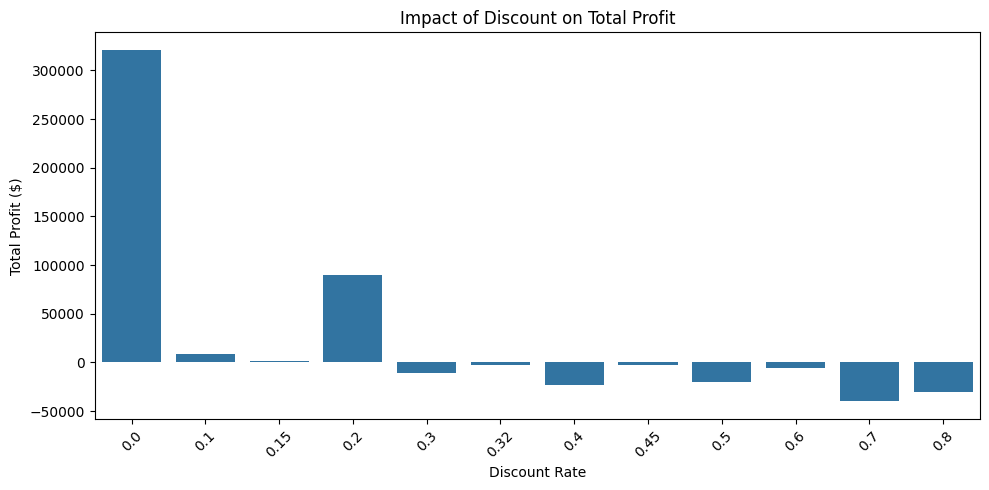

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis,
    x="Discount",
    y="Total_Profit"
)

plt.title("Impact of Discount on Total Profit")
plt.xlabel("Discount Rate")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
discount_analysis["Avg_Profit_Per_Transaction"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Transaction_Count"]
)

display(
    discount_analysis[
        [
            "Discount",
            "Transaction_Count",
            "Total_Profit",
            "Profit_Margin",
            "Avg_Profit_Per_Transaction"
        ]
    ].round(2)
)

,Discount,Transaction_Count,Total_Profit,Profit_Margin,Avg_Profit_Per_Transaction
0,0.00,4798,320987.60,29.51,66.90
1,0.10,94,9029.18,16.61,96.06
2,0.15,52,1418.99,5.15,27.29
3,0.20,3657,90337.31,11.82,24.70
4,0.30,227,-10369.28,-10.05,-45.68
5,0.32,27,-2391.14,-16.50,-88.56
6,0.40,206,-23057.05,-19.81,-111.93
7,0.45,11,-2493.11,-45.45,-226.65
8,0.50,66,-20506.43,-34.80,-310.70
9,0.60,138,-5944.66,-89.46,-43.08


In [18]:
category_discount = (
    eda_df.groupby(["Category", "Discount"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Transaction_Count=("Row ID", "count")
    )
    .reset_index()
)

category_discount["Profit_Margin"] = (
    category_discount["Total_Profit"] /
    category_discount["Total_Sales"]
) * 100

display(
    category_discount.sort_values(
        ["Category", "Discount"]
    ).round(2)
)

,Category,Discount,Total_Sales,Total_Profit,Transaction_Count,Profit_Margin
0,Furniture,0.00,256025.27,58133.08,836,22.71
1,Furniture,0.10,46634.25,7111.01,76,15.25
2,Furniture,0.15,27558.52,1418.99,52,5.15
3,Furniture,0.20,216631.02,6265.95,615,2.89
4,Furniture,0.30,99470.35,-10695.32,222,-10.75
5,Furniture,0.32,14493.46,-2391.14,27,-16.50
6,Furniture,0.40,45614.41,-16187.40,75,-35.49
7,Furniture,0.45,5484.97,-2493.11,11,-45.45
8,Furniture,0.50,20983.47,-12871.20,54,-61.34
9,Furniture,0.60,6644.70,-5944.66,138,-89.46


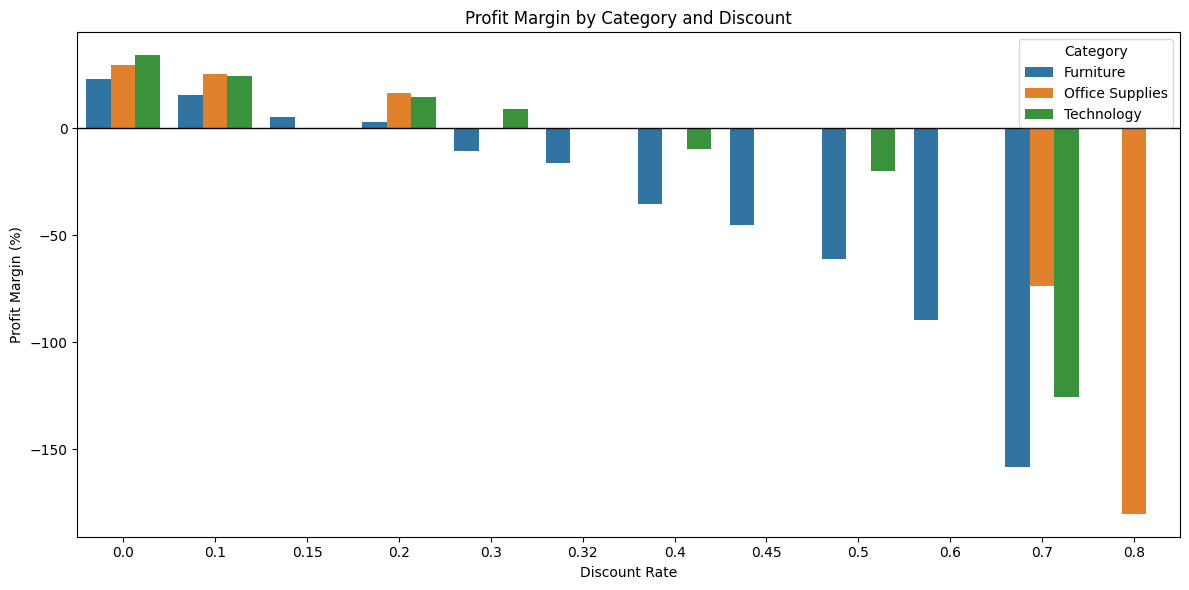

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_discount,
    x="Discount",
    y="Profit_Margin",
    hue="Category"
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Profit Margin by Category and Discount")
plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

In [20]:
# Furniture Tables discount analysis

tables_analysis = (
    eda_df[
        (eda_df["Category"] == "Furniture") &
        (eda_df["Sub-Category"] == "Tables")
    ]
    .groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Transaction_Count=("Row ID", "count"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

tables_analysis["Profit_Margin"] = (
    tables_analysis["Total_Profit"] /
    tables_analysis["Total_Sales"]
) * 100

display(tables_analysis.round(2))

,Discount,Total_Sales,Total_Profit,Transaction_Count,Total_Quantity,Profit_Margin
0,0.00,71578.76,13276.30,72,310,18.55
1,0.20,45430.23,-303.56,71,281,-0.67
2,0.30,25182.15,-3402.33,54,180,-13.51
3,0.40,45614.41,-16187.40,75,292,-35.49
4,0.45,5484.97,-2493.11,11,45,-45.45
5,0.50,13675.01,-8615.39,36,133,-63.00


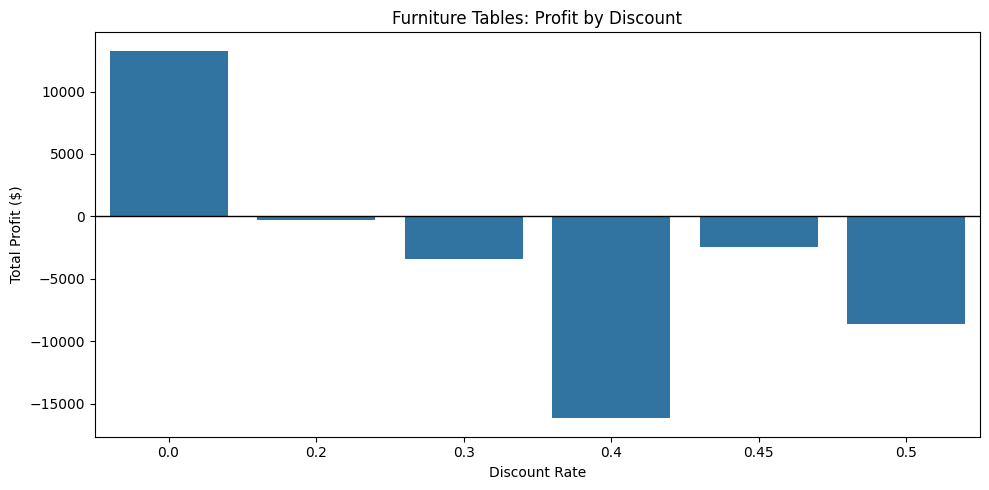

In [21]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tables_analysis,
    x="Discount",
    y="Total_Profit"
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Furniture Tables: Profit by Discount")
plt.xlabel("Discount Rate")
plt.ylabel("Total Profit ($)")

plt.tight_layout()
plt.show()

In [22]:
# Monthly Sales and Profit Analysis

monthly_analysis = (
    eda_df.groupby("Year-Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Sort chronologically
monthly_analysis = monthly_analysis.sort_values(
    by="Year-Month"
)

display(monthly_analysis.head(12).round(2))

,Year-Month,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,2014-01,14236.90,2450.19,32,284
1,2014-02,4519.89,862.31,28,159
2,2014-03,55691.01,498.73,71,585
3,2014-04,28295.34,3488.84,66,536
4,2014-05,23648.29,2738.71,69,466
5,2014-06,34595.13,4976.52,66,521
6,2014-07,33946.39,-841.48,65,550
7,2014-08,27909.47,5318.10,72,609
8,2014-09,81777.35,8328.10,130,1000
9,2014-10,31453.39,3448.26,78,573


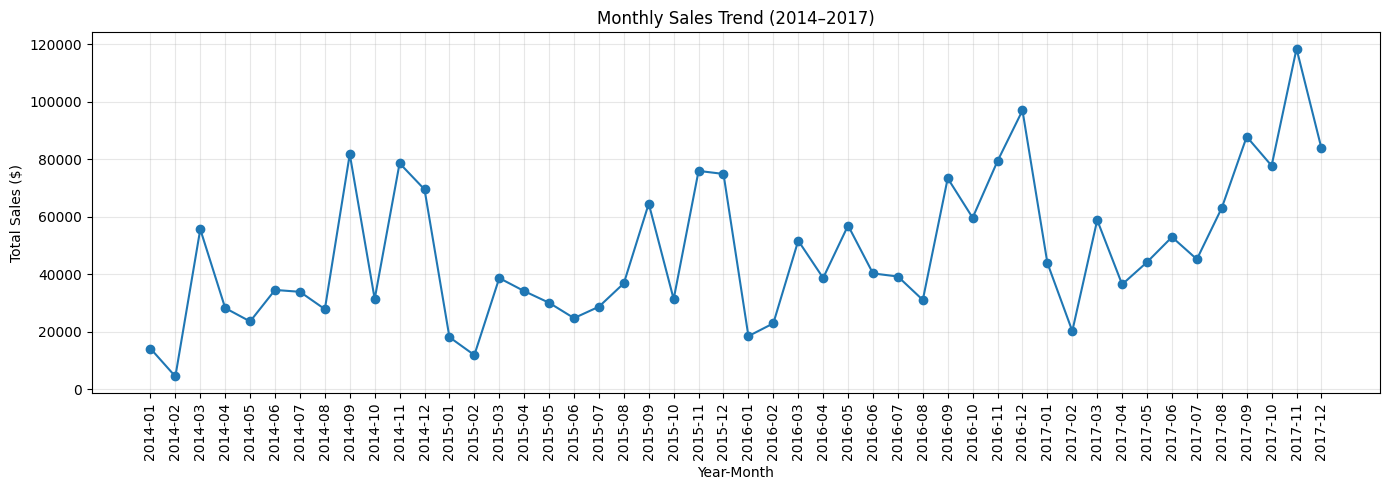

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_analysis["Year-Month"].astype(str),
    monthly_analysis["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales ($)")

plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

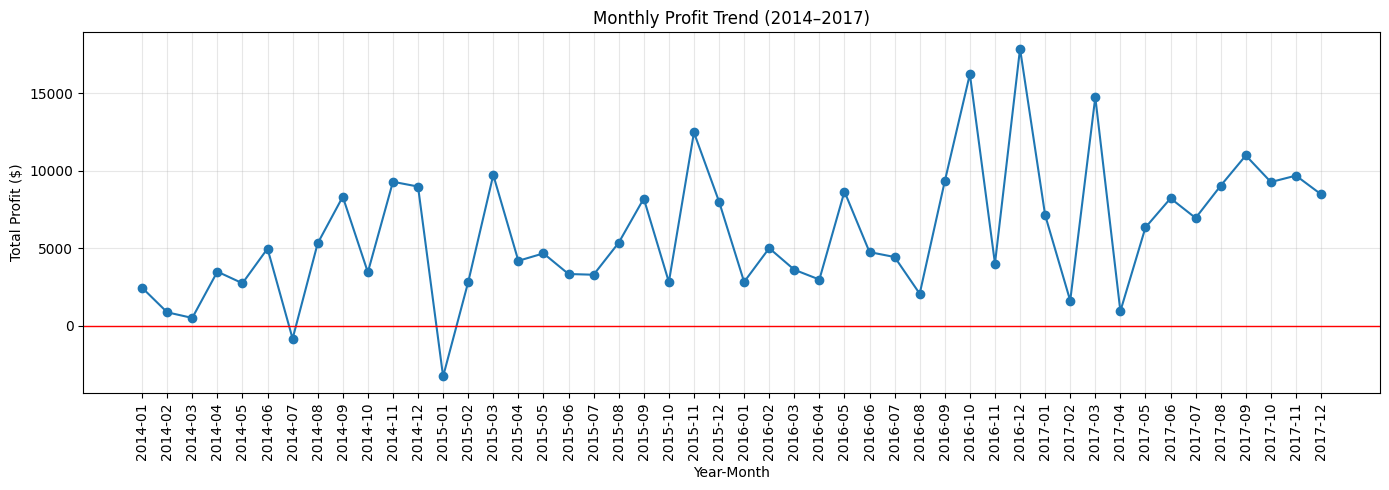

In [24]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_analysis["Year-Month"].astype(str),
    monthly_analysis["Total_Profit"],
    marker="o"
)

plt.axhline(0, color="red", linewidth=1)

plt.title("Monthly Profit Trend (2014–2017)")
plt.xlabel("Year-Month")
plt.ylabel("Total Profit ($)")

plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Best and worst months

best_sales_month = monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmax()
]

worst_sales_month = monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmin()
]

best_profit_month = monthly_analysis.loc[
    monthly_analysis["Total_Profit"].idxmax()
]

worst_profit_month = monthly_analysis.loc[
    monthly_analysis["Total_Profit"].idxmin()
]

print("BEST SALES MONTH")
print(best_sales_month)

print("\nWORST SALES MONTH")
print(worst_sales_month)

print("\nBEST PROFIT MONTH")
print(best_profit_month)

print("\nWORST PROFIT MONTH")
print(worst_profit_month)

BEST SALES MONTH
Year-Month           2017-11
Total_Sales       118447.825
Total_Profit       9690.1037
Total_Orders             261
Total_Quantity          1840
Name: 46, dtype: object

WORST SALES MONTH
Year-Month         2014-02
Total_Sales       4519.892
Total_Profit      862.3084
Total_Orders            28
Total_Quantity         159
Name: 1, dtype: object

BEST PROFIT MONTH
Year-Month           2016-12
Total_Sales        96999.043
Total_Profit      17885.3093
Total_Orders             176
Total_Quantity          1414
Name: 35, dtype: object

WORST PROFIT MONTH
Year-Month           2015-01
Total_Sales       18174.0756
Total_Profit       -3281.007
Total_Orders              29
Total_Quantity           236
Name: 12, dtype: object


In [26]:
# Year-wise business performance

yearly_analysis = (
    eda_df.groupby("Year")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Annual profit margin
yearly_analysis["Profit_Margin"] = (
    yearly_analysis["Total_Profit"] /
    yearly_analysis["Total_Sales"]
) * 100

# Year-over-year sales growth
yearly_analysis["Sales_Growth_%"] = (
    yearly_analysis["Total_Sales"].pct_change() * 100
)

display(yearly_analysis.round(2))

,Year,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin,Sales_Growth_%
0,2014,484247.50,49543.97,969,7581,10.23,NaN
1,2015,470532.51,61618.60,1038,7979,13.10,-2.83
2,2016,609205.60,81795.17,1315,9837,13.43,29.47
3,2017,733215.26,93439.27,1687,12476,12.74,20.36


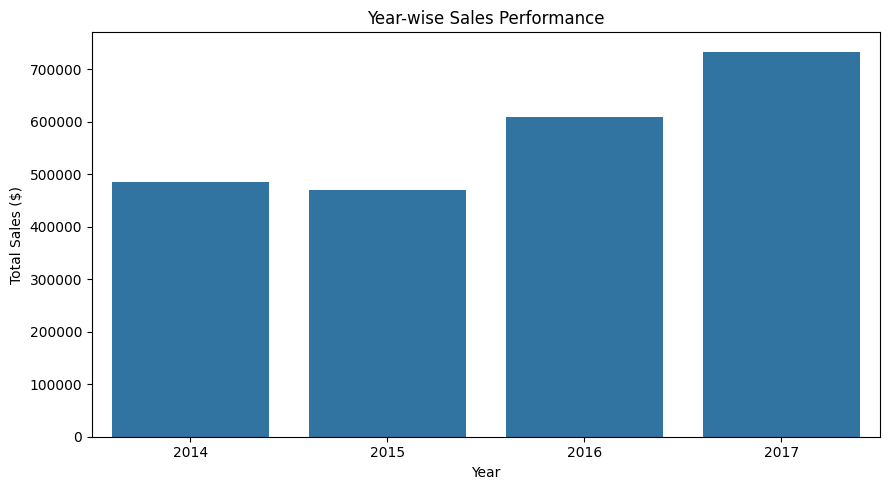

In [27]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_analysis,
    x="Year",
    y="Total_Sales"
)

plt.title("Year-wise Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

In [28]:
# Display best and worst months clearly

results = {
    "Highest Sales": monthly_analysis.loc[
        monthly_analysis["Total_Sales"].idxmax()
    ],
    "Lowest Sales": monthly_analysis.loc[
        monthly_analysis["Total_Sales"].idxmin()
    ],
    "Highest Profit": monthly_analysis.loc[
        monthly_analysis["Total_Profit"].idxmax()
    ],
    "Lowest Profit": monthly_analysis.loc[
        monthly_analysis["Total_Profit"].idxmin()
    ]
}

for metric, row in results.items():
    print(f"\n{metric}")
    print(f"Month: {row['Year-Month']}")
    print(f"Sales: ${row['Total_Sales']:,.2f}")
    print(f"Profit: ${row['Total_Profit']:,.2f}")


Highest Sales
Month: 2017-11
Sales: $118,447.82
Profit: $9,690.10

Lowest Sales
Month: 2014-02
Sales: $4,519.89
Profit: $862.31

Highest Profit
Month: 2016-12
Sales: $96,999.04
Profit: $17,885.31

Lowest Profit
Month: 2015-01
Sales: $18,174.08
Profit: $-3,281.01


In [29]:
region_analysis = (
    eda_df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"]
) * 100

region_analysis = region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

display(region_analysis.round(2))

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Total_Customers,Profit_Margin
3,West,725457.82,108418.45,1611,12266,686,14.94
1,East,678781.24,91522.78,1401,10618,674,13.48
0,Central,501239.89,39706.36,1175,8780,629,7.92
2,South,391721.90,46749.43,822,6209,512,11.93


In [30]:
state_analysis = (
    eda_df.groupby("State")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

state_analysis["Profit_Margin"] = (
    state_analysis["Total_Profit"] /
    state_analysis["Total_Sales"]
) * 100

# Top 10 states by sales
top_states = state_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).head(10)

display(top_states.round(2))

,State,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
3,California,457687.63,76381.39,1021,16.69
30,New York,310876.27,74038.55,562,23.82
41,Texas,170188.05,-25729.36,487,-15.12
45,Washington,138641.27,33402.65,256,24.09
36,Pennsylvania,116511.91,-15559.96,288,-13.35
8,Florida,89473.71,-3399.30,200,-3.80
11,Illinois,80166.10,-12607.89,276,-15.73
33,Ohio,78258.14,-16971.38,236,-21.69
20,Michigan,76269.61,24463.19,117,32.07
44,Virginia,70636.72,18597.95,115,26.33


In [31]:
loss_states = state_analysis[
    state_analysis["Total_Profit"] < 0
].sort_values(
    by="Total_Profit"
)

display(loss_states.round(2))

,State,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
41,Texas,170188.05,-25729.36,487,-15.12
33,Ohio,78258.14,-16971.38,236,-21.69
36,Pennsylvania,116511.91,-15559.96,288,-13.35
11,Illinois,80166.10,-12607.89,276,-15.73
31,North Carolina,55603.16,-7490.91,136,-13.47
4,Colorado,32108.12,-6527.86,79,-20.33
40,Tennessee,30661.87,-5341.69,91,-17.42
1,Arizona,35282.00,-3427.92,108,-9.72
8,Florida,89473.71,-3399.30,200,-3.80
35,Oregon,17431.15,-1190.47,56,-6.83


In [32]:
from pathlib import Path
from data_loader import load_data

# Locate project directory
cwd = Path.cwd()

PROJECT_DIR = (
    cwd.parent if cwd.name.lower() == "src"
    else cwd
)

# Dataset path
DATA_PATH = (
    PROJECT_DIR / "Data" / "Sample - Superstore.csv"
)

# Load dataset using our module
df_test = load_data(DATA_PATH)

# Verify output
print("\nDataset shape:", df_test.shape)

display(df_test.head())

Dataset loaded successfully!
Records: 9994
Columns: 21

Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [33]:
from data_cleaning import clean_data

# Clean and transform loaded dataset
cleaned_df = clean_data(df_test)

# Verify results
display(cleaned_df.head())

print("\nFinal Dataset Information:")
cleaned_df.info()

Starting data validation...

DATA QUALITY SUMMARY
Missing Values: 0
Duplicate Rows: 0
Invalid Order Dates: 0
Invalid Ship Dates: 0
Invalid Sales: 0
Invalid Quantity: 0

Data validation completed successfully!
Data transformation completed successfully!
Final Shape: (9994, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,2015-10



Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object       

In [ ]:
from report_metrics import (
    calculate_kpis,
    category_analysis,
    subcategory_analysis,
    region_analysis,
    state_analysis,
    monthly_analysis,
    yearly_analysis
)

# Calculate all business metrics
kpis = calculate_kpis(cleaned_df)

category_report = category_analysis(cleaned_df)
subcategory_report = subcategory_analysis(cleaned_df)
region_report = region_analysis(cleaned_df)
state_report = state_analysis(cleaned_df)
monthly_report = monthly_analysis(cleaned_df)
yearly_report = yearly_analysis(cleaned_df)

print("All business metrics calculated successfully!")

All business metrics calculated successfully!


In [35]:
# Verify overall KPIs

assert round(kpis["Total Sales"], 2) == 2297200.86
assert round(kpis["Total Profit"], 2) == 286397.02
assert kpis["Total Orders"] == 5009
assert kpis["Total Customers"] == 793

print("All KPI validation tests passed!")

All KPI validation tests passed!


In [36]:
# Verify aggregation totals

assert round(category_report["Total_Sales"].sum(), 2) == 2297200.86

assert round(category_report["Total_Profit"].sum(), 2) == 286397.02

assert round(region_report["Total_Sales"].sum(), 2) == 2297200.86

assert round(monthly_report["Total_Sales"].sum(), 2) == 2297200.86

print("All aggregation tests passed!")

All aggregation tests passed!


In [37]:
display(category_report.round(2))
display(subcategory_report.head(10).round(2))
display(region_report.round(2))
display(state_report.head(10).round(2))
display(monthly_report.head(5))
display(yearly_report.round(2))

,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
2,Technology,836154.03,145454.95,6939,1544,17.40
0,Furniture,741999.80,18451.27,8028,1764,2.49
1,Office Supplies,719047.03,122490.80,22906,3742,17.04


,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
16,Technology,Phones,330007.05,44515.73,3289,814,13.49
1,Furniture,Chairs,328449.10,26590.17,2356,576,8.10
11,Office Supplies,Storage,223843.61,21278.83,3158,777,9.51
3,Furniture,Tables,206965.53,-17725.48,1241,307,-8.56
6,Office Supplies,Binders,203412.73,30221.76,5974,1316,14.86
15,Technology,Machines,189238.63,3384.76,440,112,1.79
13,Technology,Accessories,167380.32,41936.64,2976,718,25.05
14,Technology,Copiers,149528.03,55617.82,234,68,37.20
0,Furniture,Bookcases,114880.00,-3472.56,868,224,-3.02
4,Office Supplies,Appliances,107532.16,18138.01,1729,451,16.87


,Region,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Profit_Margin
3,West,725457.82,108418.45,1611,686,14.94
1,East,678781.24,91522.78,1401,674,13.48
0,Central,501239.89,39706.36,1175,629,7.92
2,South,391721.90,46749.43,822,512,11.93


,State,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
3,California,457687.63,76381.39,1021,16.69
30,New York,310876.27,74038.55,562,23.82
41,Texas,170188.05,-25729.36,487,-15.12
45,Washington,138641.27,33402.65,256,24.09
36,Pennsylvania,116511.91,-15559.96,288,-13.35
8,Florida,89473.71,-3399.30,200,-3.80
11,Illinois,80166.10,-12607.89,276,-15.73
33,Ohio,78258.14,-16971.38,236,-21.69
20,Michigan,76269.61,24463.19,117,32.07
44,Virginia,70636.72,18597.95,115,26.33


,Year-Month,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,2014-01,14236.895,2450.1907,32,284
1,2014-02,4519.892,862.3084,28,159
2,2014-03,55691.009,498.7299,71,585
3,2014-04,28295.345,3488.8352,66,536
4,2014-05,23648.287,2738.7096,69,466


,Year,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin,Sales_Growth_%
0,2014,484247.50,49543.97,969,7581,10.23,NaN
1,2015,470532.51,61618.60,1038,7979,13.10,-2.83
2,2016,609205.60,81795.17,1315,9837,13.43,29.47
3,2017,733215.26,93439.27,1687,12476,12.74,20.36


In [38]:
from pathlib import Path

from excel_formatter import export_report

# Project paths
cwd = Path.cwd()

PROJECT_DIR = (
    cwd.parent if cwd.name.lower() == "src"
    else cwd
)

OUTPUT_PATH = (
    PROJECT_DIR / "reports" / "Superstore_MIS_Report.xlsx"
)

# Generate report for December 2017
report_path = export_report(
    df=cleaned_df,
    kpis=kpis,
    category_report=category_report,
    subcategory_report=subcategory_report,
    region_report=region_report,
    state_report=state_report,
    monthly_report=monthly_report,
    yearly_report=yearly_report,
    output_path=OUTPUT_PATH,
    selected_month="2017-12"
)

print("\nReport saved at:", report_path)

Excel MIS report generated successfully!
File: c:\Users\satya\Downloads\excel-report-automation\reports\Superstore_MIS_Report.xlsx
Selected Month: 2017-12
Sheets: 8

Report saved at: c:\Users\satya\Downloads\excel-report-automation\reports\Superstore_MIS_Report.xlsx
